# COU 07506 Digital Signal Processing: Week 01: Lab 0: Setting Up the DSP Laboratory
Name: HOSANA HEREMAN KOMBA  
Registration No.: 240242445476                           

Class: BEng24COE-1      

Instructor: DR.HAJI FIMBOMBAYA

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab

1. **Mobile Phone**: Captures, digitizes, and processes voice signals during phone calls and voice recordings.
2. **Personal Computer (Laptop)**: Handles real-time digital audio streams received from the built-in microphone and sent to the speakers.
3. **Network Infrastructure (Wi-Fi Router & Mobile Networks)**: Processes high-frequency electromagnetic radio signals to transmit and receive data packet streams.

## Task 1.1: Your first notebook

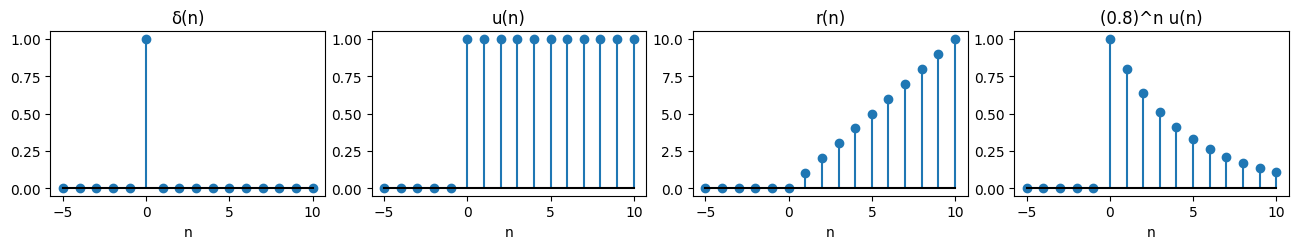

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)    # unit impulse
step  = (n >= 0).astype(float)    # unit step
ramp  = n * step                  # unit ramp
expo  = 0.8**n * step             # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

## Task 1.2: Change the parameters

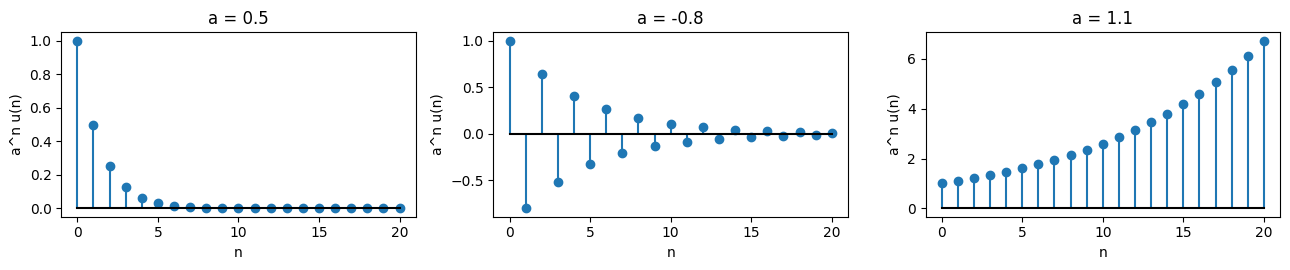

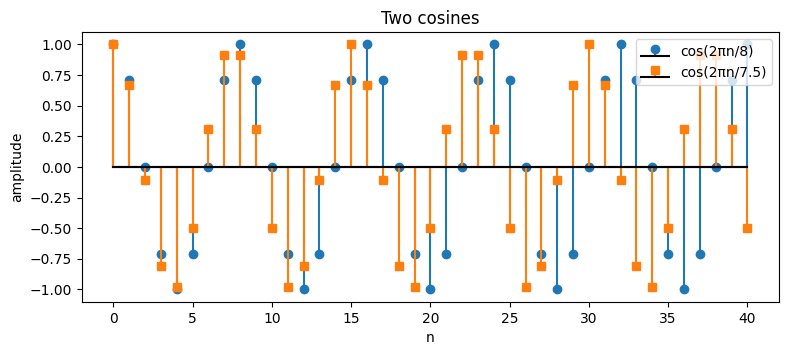

In [3]:
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n"); ax.set_ylabel("a^n u(n)")
plt.tight_layout(); plt.show()

n = np.arange(0, 41)
plt.stem(n, np.cos(2*np.pi*n/8), linefmt="C0-", markerfmt="C0o", basefmt="k-", label="cos(2πn/8)")
plt.stem(n, np.cos(2*np.pi*n/7.5), linefmt="C1-", markerfmt="C1s", basefmt="k-", label="cos(2πn/7.5)")
plt.title("Two cosines"); plt.xlabel("n"); plt.ylabel("amplitude")
plt.legend(); plt.show()

## Task 1.3: Working with audio

Using my recording
fs = 44100 Hz, duration = 5.00 s, samples = 220500


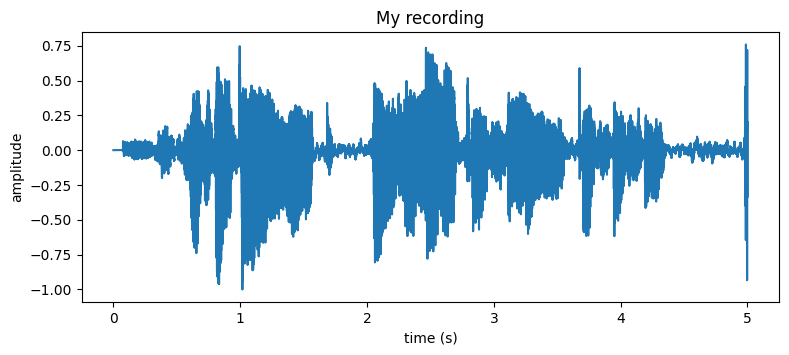

In [4]:
import os
fname = "hosanavoice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)            # stereo -> mono
    x = x[:5*fs]                      # keep the first 5 seconds
    x = x / np.max(np.abs(x))         # normalise to [-1, 1]
    print("Using my recording")
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
    print("Using fallback signal")

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()
display(Audio(x, rate=fs))

## Analysis questions

1. For a sampling rate of $f_s = 44100$ Hz, storing a one-minute ($60$ seconds) mono audio track requires a total of $44100 \times 60 = 2,646,000$ discrete data points (samples).

2. The discrete-time sequence $x[n]$ is mathematically defined only at integer intervals of $n$, and contains no intermediate values. A stem plot is the correct representation because it highlights these isolated points, whereas a continuous line plot would incorrectly imply that defined values exist between sample intervals.

3. An exponential sequence with a base $|a| > 1$ (such as $a = 1.1$) represents an unstable impulse response. This is because the sequence values grow exponentially towards infinity, violating the Bounded-Input Bounded-Output (BIBO) stability criteria where the sum of the absolute impulse response must be finite (i.e., $\sum_{n=0}^{\infty} |h[n]| = \infty$).